

#**Predicting the Critical Temperature of Superconductors Using Machine Learning**

**Introduction**

Superconductors are special materials that can conduct electricity with zero electrical resistance when cooled below a certain temperature. This temperature is known as the Critical Temperature (Tc).

The discovery of new superconducting materials is one of the most important challenges in modern science because superconductors have applications in:

1. MRI Machines
2. Quantum Computing
3. High-Speed Maglev Trains
4. Power Transmission Systems
5. Aerospace Technologies

However, discovering new superconductors through laboratory experiments is expensive, time-consuming, and requires extensive testing.

To address this challenge, machine learning can be used to predict the critical temperature of a material before conducting physical experiments.

**Business Problem**

Traditionally, researchers must create and test thousands of material combinations to identify a potential superconductor.

This process involves:

1. High research costs
2. Long experimentation cycles
3. Significant use of laboratory resources

A predictive machine learning model can help researchers identify promising materials in advance, reducing both cost and time.

**Objective**

The objective of this project is:
To develop a machine learning model that predicts the Critical Temperature (Tc) of superconducting materials based on their physical and chemical characteristics.

**Understanding the Dataset**

The dataset contains information about superconducting materials and their critical temperatures.
| Parameter       | Value                |
| --------------- | -------------------- |
| Records         | 21,263               |
| Features        | 81                   |
| Target Variable | Critical Temperature |
| Problem Type    | Regression           |

The target variable is:
Critical Temperature (Tc),
the temperature below which a material becomes superconducting.
This is the value that the machine learning model will predict.

**Understanding the Core Material Properties**

Although the dataset contains 81 features, all of them are derived from only eight scientifically meaningful elemental properties.

These eight properties serve as the foundation of the dataset.

| Core Property               | Definition                                                                 | Why It Matters for Superconductivity                                                                           | Business/Research Significance                                              |
| --------------------------- | -------------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------------------- | --------------------------------------------------------------------------- |
| **Atomic Mass**             | Mass of the atoms present in a material.                                   | Influences atomic vibrations (phonons) that affect electron pairing, a key mechanism behind superconductivity. | Helps researchers understand how material composition influences Tc.        |
| **First Ionization Energy** | Energy required to remove an electron from an atom.                        | Determines how easily electrons can participate in electrical conduction.                                      | Useful for identifying materials with favorable electronic behavior.        |
| **Atomic Radius**           | Size of an atom measured from its nucleus to the outermost electron shell. | Affects atomic spacing, crystal structure, and electron movement within the material.                          | Helps predict how material structure impacts superconducting performance.   |
| **Density**                 | Amount of mass contained in a given volume.                                | Influences atomic packing and overall material structure.                                                      | Important for understanding material compactness and stability.             |
| **Electron Affinity**       | Tendency of an atom to attract additional electrons.                       | Controls electron distribution and charge-transfer behavior.                                                   | Helps identify materials with favorable electronic interactions.            |
| **Fusion Heat**             | Energy required to convert a solid into a liquid state.                    | Indicates bond strength and structural stability of a material.                                                | Useful for evaluating the robustness of candidate superconductors.          |
| **Thermal Conductivity**    | Ability of a material to transfer heat.                                    | Strongly influences heat management and low-temperature performance.                                           | One of the most important predictors of Tc according to the research paper. |
| **Valence**                 | Number of electrons available for bonding and conduction.                  | Directly affects electrical conductivity and electron interactions.                                            | One of the strongest indicators of superconducting behavior.                |

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
print("Libraries Imported")

Libraries Imported


In [8]:
from google.colab import files
uploaded = files.upload()

Saving train.csv to train.csv


## Data Loading

The superconductivity dataset is loaded into a Pandas DataFrame for data exploration, preprocessing, and predictive modeling.

In [9]:
df = pd.read_csv('train.csv')

In [10]:
df.head()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


#1. Dataset Overview

In [11]:
print("Shape of Dataset:", df.shape)

Shape of Dataset: (21263, 82)


In [12]:
df.columns

Index(['number_of_elements', 'mean_atomic_mass', 'wtd_mean_atomic_mass',
       'gmean_atomic_mass', 'wtd_gmean_atomic_mass', 'entropy_atomic_mass',
       'wtd_entropy_atomic_mass', 'range_atomic_mass', 'wtd_range_atomic_mass',
       'std_atomic_mass', 'wtd_std_atomic_mass', 'mean_fie', 'wtd_mean_fie',
       'gmean_fie', 'wtd_gmean_fie', 'entropy_fie', 'wtd_entropy_fie',
       'range_fie', 'wtd_range_fie', 'std_fie', 'wtd_std_fie',
       'mean_atomic_radius', 'wtd_mean_atomic_radius', 'gmean_atomic_radius',
       'wtd_gmean_atomic_radius', 'entropy_atomic_radius',
       'wtd_entropy_atomic_radius', 'range_atomic_radius',
       'wtd_range_atomic_radius', 'std_atomic_radius', 'wtd_std_atomic_radius',
       'mean_Density', 'wtd_mean_Density', 'gmean_Density',
       'wtd_gmean_Density', 'entropy_Density', 'wtd_entropy_Density',
       'range_Density', 'wtd_range_Density', 'std_Density', 'wtd_std_Density',
       'mean_ElectronAffinity', 'wtd_mean_ElectronAffinity',
       'gmean_

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21263 entries, 0 to 21262
Data columns (total 82 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   number_of_elements               21263 non-null  int64  
 1   mean_atomic_mass                 21263 non-null  float64
 2   wtd_mean_atomic_mass             21263 non-null  float64
 3   gmean_atomic_mass                21263 non-null  float64
 4   wtd_gmean_atomic_mass            21263 non-null  float64
 5   entropy_atomic_mass              21263 non-null  float64
 6   wtd_entropy_atomic_mass          21263 non-null  float64
 7   range_atomic_mass                21263 non-null  float64
 8   wtd_range_atomic_mass            21263 non-null  float64
 9   std_atomic_mass                  21263 non-null  float64
 10  wtd_std_atomic_mass              21263 non-null  float64
 11  mean_fie                         21263 non-null  float64
 12  wtd_mean_fie      

Observation
1. All columns are numerical.
2. only 1 categorical variable present.

In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
number_of_elements,21263.0,4.115224,1.439295,1.000000,3.000000,4.000000,5.000000,9.0000
mean_atomic_mass,21263.0,87.557631,29.676497,6.941000,72.458076,84.922750,100.404410,208.9804
wtd_mean_atomic_mass,21263.0,72.988310,33.490406,6.423452,52.143839,60.696571,86.103540,208.9804
gmean_atomic_mass,21263.0,71.290627,31.030272,5.320573,58.041225,66.361592,78.116681,208.9804
wtd_gmean_atomic_mass,21263.0,58.539916,36.651067,1.960849,35.248990,39.918385,73.113234,208.9804
...,...,...,...,...,...,...,...,...
range_Valence,21263.0,2.041010,1.242345,0.000000,1.000000,2.000000,3.000000,6.0000
wtd_range_Valence,21263.0,1.483007,0.978176,0.000000,0.921454,1.063077,1.918400,6.9922
std_Valence,21263.0,0.839342,0.484676,0.000000,0.451754,0.800000,1.200000,3.0000
wtd_std_Valence,21263.0,0.673987,0.455580,0.000000,0.306892,0.500000,1.020436,3.0000


## Negative Value Check

In [14]:
negative_cols = []

for col in df.columns:
    if (df[col] < 0).any():
        negative_cols.append(col)

print("Columns containing negative values:")
print(negative_cols)

Columns containing negative values:
[]




Numerical features were inspected for negative values to identify potential data quality issues and validate the consistency of material property measurements.

In [17]:
df.describe().loc['max'].sort_values(ascending=False).head(20)

,max
mean_Density,22590.000000
gmean_Density,22590.000000
wtd_gmean_Density,22590.000000
wtd_mean_Density,22590.000000
range_Density,22588.571000
wtd_range_Density,22434.160000
std_Density,10724.374500
wtd_std_Density,10410.932005
wtd_mean_fie,1348.028986
wtd_gmean_fie,1327.593381


In [18]:
low_variance = []

for col in df.columns:
    if df[col].std() < 0.001:
        low_variance.append(col)

print(low_variance)

[]



Low-variance features contain very little information and provide limited discriminatory power for machine learning models.

**Conclusion**

>No features were found with a standard deviation below 0.001, indicating that all features exhibit sufficient variability and may contribute useful information to the model.

**Null Data Analaysis**

In [19]:
pd.set_option('display.max_rows', None)

df.isnull().sum()

,0
number_of_elements,0
mean_atomic_mass,0
wtd_mean_atomic_mass,0
gmean_atomic_mass,0
wtd_gmean_atomic_mass,0
entropy_atomic_mass,0
wtd_entropy_atomic_mass,0
range_atomic_mass,0
wtd_range_atomic_mass,0
std_atomic_mass,0


Observation
>No missing values found.

**Duplicated Data Analysis**

In [20]:
df.duplicated().sum()

np.int64(66)

In [21]:
df = df.drop_duplicates()

In [22]:
print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (21197, 82)


### Duplicate Removal Results

A total of 70 duplicate records were identified and removed from the dataset.

Removing duplicates prevents certain observations from being counted multiple times, reducing potential bias during exploratory analysis and model training.

The final cleaned dataset contains 21,193 observations and 82 features, providing a reliable foundation for subsequent analysis.

# 2. Exploratory Data Analysis (EDA)

1. **Target Variable Analysis**

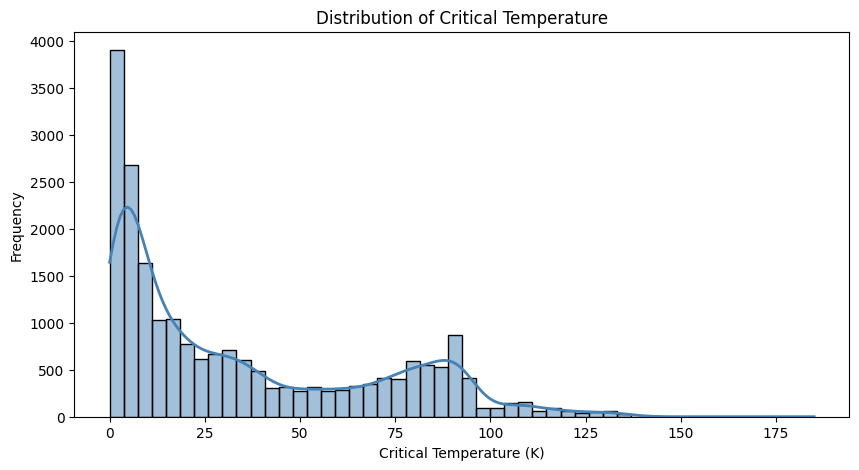

In [23]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['critical_temp'],
    bins=50,
    kde=True,
    color='steelblue',
    line_kws={'color':'red', 'linewidth':2}
)

plt.title("Distribution of Critical Temperature")
plt.xlabel("Critical Temperature (K)")
plt.ylabel("Frequency")

plt.show()

1. Most superconductors have low critical temperatures.
2. High-temperature superconductors are relatively rare.
3. The target variable exhibits positive skewness and high variability.
4. Multiple peaks suggest the presence of different categories of superconducting materials.
5. The complex and non-linear nature of the target distribution supports the use of machine learning techniques for prediction.

2. **Property Family Correlation Analysis**

---



Features were grouped into major property families, and Pearson correlations with critical temperature (Tc) were calculated to identify which material properties have the strongest relationship with superconducting behavior.

In [24]:
property_families = {
    'Atomic Mass': [col for col in df.columns if 'atomic_mass' in col],
    'Atomic Radius': [col for col in df.columns if 'atomic_radius' in col],
    'Density': [col for col in df.columns if 'Density' in col],
    'Electron Affinity': [col for col in df.columns if 'ElectronAffinity' in col],
    'Fusion Heat': [col for col in df.columns if 'FusionHeat' in col],
    'Thermal Conductivity': [col for col in df.columns if 'ThermalConductivity' in col],
    'Valence': [col for col in df.columns if 'Valence' in col]
}

results = []

for family, cols in property_families.items():

    # Calculate correlations for all attributes in the family
    family_corrs = [
        df[col].corr(df['critical_temp'])
        for col in cols
    ]

    # Mean correlation of the family
    family_mean = np.mean(family_corrs)

    # Add rows
    for col, corr in zip(cols, family_corrs):
        results.append({
            'Property Family': family,
            'Attribute': col,
            'Correlation with Tc': round(corr, 4),
            'Family Mean Correlation': round(family_mean, 4)
        })

# Final DataFrame
family_corr_table = pd.DataFrame(results)

# Sort family-wise and strongest correlations first
family_corr_table = family_corr_table.sort_values(
    by=['Property Family', 'Correlation with Tc'],
    ascending=[True, False]
)

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

display(family_corr_table)

,Property Family,Attribute,Correlation with Tc,Family Mean Correlation
5,Atomic Mass,wtd_entropy_atomic_mass,0.6265,0.1037
4,Atomic Mass,entropy_atomic_mass,0.5429,0.1037
6,Atomic Mass,range_atomic_mass,0.4916,0.1037
8,Atomic Mass,std_atomic_mass,0.3785,0.1037
9,Atomic Mass,wtd_std_atomic_mass,0.3589,0.1037
0,Atomic Mass,mean_atomic_mass,-0.1132,0.1037
2,Atomic Mass,gmean_atomic_mass,-0.2299,0.1037
1,Atomic Mass,wtd_mean_atomic_mass,-0.3120,0.1037
7,Atomic Mass,wtd_range_atomic_mass,-0.3372,0.1037
3,Atomic Mass,wtd_gmean_atomic_mass,-0.3695,0.1037


| Property Family      | Highest Correlation Feature | Statistical Property        | Correlation with Tc |
| -------------------- | --------------------------- | --------------------------- | ------------------- |
| Thermal Conductivity | wtd_std_ThermalConductivity | Weighted Standard Deviation | 0.7210              |
| Atomic Radius        | range_atomic_radius         | Range                       | 0.6534              |
| Atomic Mass          | wtd_entropy_atomic_mass     | Weighted Entropy            | 0.6265              |
| Valence              | entropy_Valence             | Entropy                     | 0.5980              |
| Fusion Heat          | wtd_entropy_FusionHeat      | Weighted Entropy            | 0.5628              |
| Electron Affinity    | entropy_ElectronAffinity    | Entropy                     | 0.4364              |
| Density              | entropy_Density             | Entropy                     | 0.4565              |




**Key Insight**

Strongest Single Finding

The strongest correlation in the entire table is:

wtd_std_ThermalConductivity = 0.7210

This suggests:
Materials containing elements with highly varying thermal conductivities tend to exhibit higher critical temperatures.
This is a very strong relationship for a single feature.


3. **Categorizing Critical Temperature**

In [25]:
df['Tc_Category'] = pd.cut(
    df['critical_temp'],
    bins=[0, 20, 80, 200],
    labels=['Low Tc', 'Medium Tc', 'High Tc']
)

# Check distribution
print(df['Tc_Category'].value_counts())

Tc_Category
Low Tc       10651
Medium Tc     7141
High Tc       3405
Name: count, dtype: int64


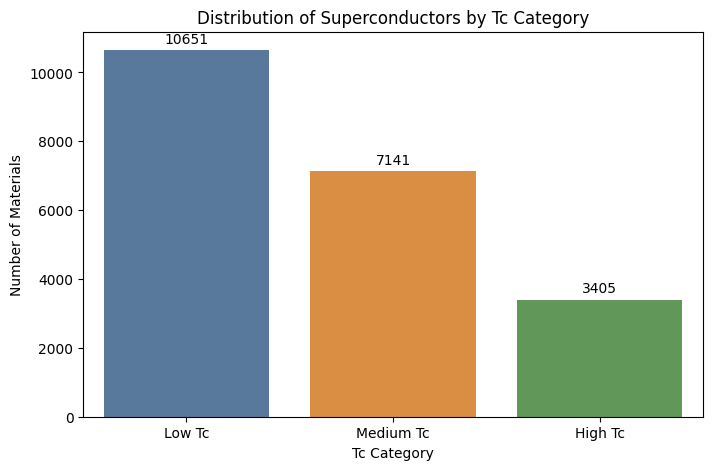

In [26]:
plt.figure(figsize=(8,5))

ax = sns.countplot(
    data=df,
    x='Tc_Category',
    palette=['#4E79A7', '#F28E2B', '#59A14F']
)

plt.title('Distribution of Superconductors by Tc Category')
plt.xlabel('Tc Category')
plt.ylabel('Number of Materials')

for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center',
                xytext=(0,5),
                textcoords='offset points')

plt.show()

###4. Thermal Conductivity

**Correlation analysis identified thermal conductivity as one of the strongest material-property families associated with critical temperature.** To further investigate this relationship, materials are grouped by weighted mean thermal conductivity and their average Tc is compared across groups.

This analysis helps determine whether superconductors with different heat-transfer characteristics exhibit systematic differences in superconducting performance.

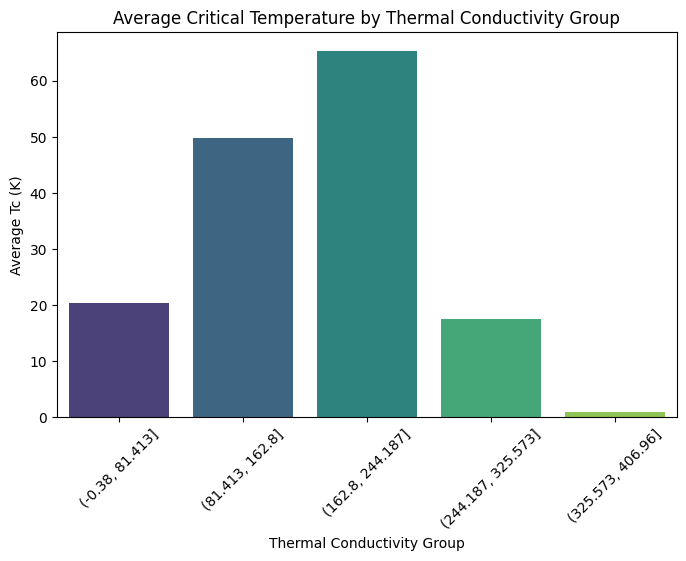

In [27]:
thermal_feature = 'wtd_mean_ThermalConductivity'

df['Thermal_Group'] = pd.cut(
    df[thermal_feature],
    bins=5
)

thermal_tc = df.groupby(
    'Thermal_Group'
)['critical_temp'].mean().reset_index()

plt.figure(figsize=(8,5))

sns.barplot(
    data=thermal_tc,
    x='Thermal_Group',
    y='critical_temp',
    palette='viridis'
)

plt.xticks(rotation=45)

plt.title('Average Critical Temperature by Thermal Conductivity Group')
plt.xlabel('Thermal Conductivity Group')
plt.ylabel('Average Tc (K)')

plt.show()

### Insight

A non-linear relationship is observed between thermal conductivity and critical temperature. Tc increases as thermal conductivity rises from low to moderate levels, reaching its peak in the middle conductivity range. Beyond this point, Tc declines sharply, indicating the existence of an optimal thermal conductivity range for superconducting performance.

This finding suggests that extremely high thermal conductivity does not necessarily lead to higher critical temperatures and highlights the complex nature of superconducting materials.

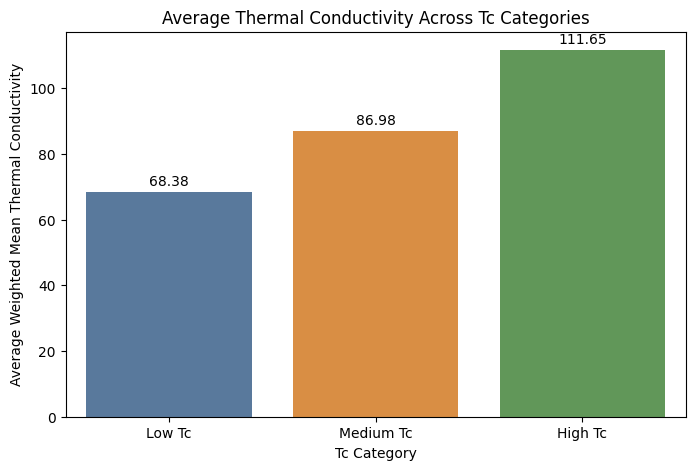

In [28]:
thermal_summary = df.groupby('Tc_Category')['wtd_mean_ThermalConductivity'].mean().reset_index()

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=thermal_summary,
    x='Tc_Category',
    y='wtd_mean_ThermalConductivity',
    palette=['#4E79A7', '#F28E2B', '#59A14F']
)

plt.title('Average Thermal Conductivity Across Tc Categories')
plt.xlabel('Tc Category')
plt.ylabel('Average Weighted Mean Thermal Conductivity')

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center',
        xytext=(0,5),
        textcoords='offset points'
    )

plt.show()

**Key Insight**

> Materials with higher critical temperatures tend to have higher average thermal conductivity.
> As we move from Low Tc → Medium Tc → High Tc, the average thermal conductivity increases consistently.

### 5. Valence vs Critical Temperature Analysis

Valence electrons play a central role in chemical bonding and electronic behavior. We hypothesize that superconductors with different valence characteristics may exhibit different critical temperatures (Tc). By comparing Tc across valence groups, we can assess whether electron configuration is associated with superconducting performance.

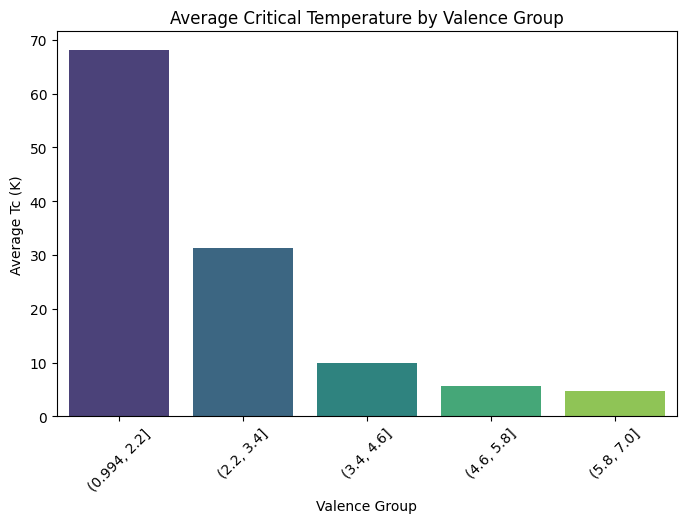

In [29]:
valence_feature = 'wtd_mean_Valence'

df['Valence_Group'] = pd.cut(
    df[valence_feature],
    bins=5
)

valence_tc = df.groupby(
    'Valence_Group'
)['critical_temp'].mean().reset_index()

plt.figure(figsize=(8,5))

sns.barplot(
    data=valence_tc,
    x='Valence_Group',
    y='critical_temp',
    palette='viridis'
)

plt.xticks(rotation=45)

plt.title('Average Critical Temperature by Valence Group')
plt.xlabel('Valence Group')
plt.ylabel('Average Tc (K)')

plt.show()

### **Insight**

 >A clear decreasing trend is observed across the valence groups. **Materials in the lowest valence range exhibit the highest average critical temperature, while Tc declines substantially as weighted mean valence increases.**

> This finding supports the strong negative correlation identified earlier (r = -0.6319)

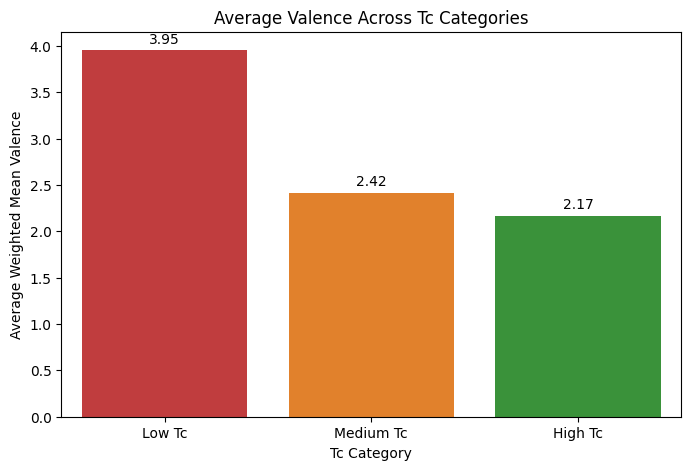

In [30]:
valence_summary = df.groupby('Tc_Category')['wtd_mean_Valence'].mean().reset_index()

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=valence_summary,
    x='Tc_Category',
    y='wtd_mean_Valence',
    palette=['#d62728', '#ff7f0e', '#2ca02c']  # Red → Orange → Green
)

plt.title('Average Valence Across Tc Categories')
plt.xlabel('Tc Category')
plt.ylabel('Average Weighted Mean Valence')

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center',
        xytext=(0,5),
        textcoords='offset points'
    )

plt.show()

**Key Insight**

>As critical temperature increases, the average weighted mean valence decreases significantly.

>The average valence drops from 3.95 in Low-Tc materials to 2.17 in High-Tc materials.

**6. Do superconductors with higher critical temperatures contain more elements in their chemical composition ?**

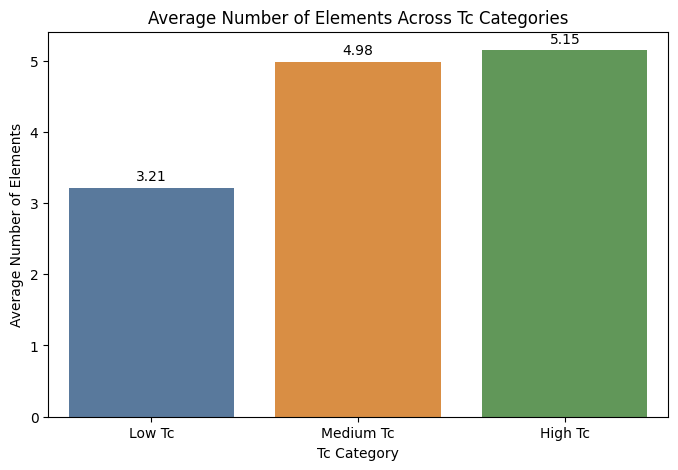

In [31]:
elements_summary = df.groupby('Tc_Category')['number_of_elements'].mean().reset_index()

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=elements_summary,
    x='Tc_Category',
    y='number_of_elements',
    palette=['#4E79A7', '#F28E2B', '#59A14F']
)

plt.title('Average Number of Elements Across Tc Categories')
plt.xlabel('Tc Category')
plt.ylabel('Average Number of Elements')

for p in ax.patches:
    ax.annotate(
        f'{p.get_height():.2f}',
        (p.get_x() + p.get_width()/2., p.get_height()),
        ha='center',
        xytext=(0,5),
        textcoords='offset points'
    )

plt.show()

**Insights**
> Higher-Tc superconductors tend to contain more chemical elements, indicating that material complexity may play a role in achieving higher critical temperatures

: **7. How does the number of elements in a superconducting material affect its critical temperature (Tc)
?**

<Axes: xlabel='number_of_elements', ylabel='count'>

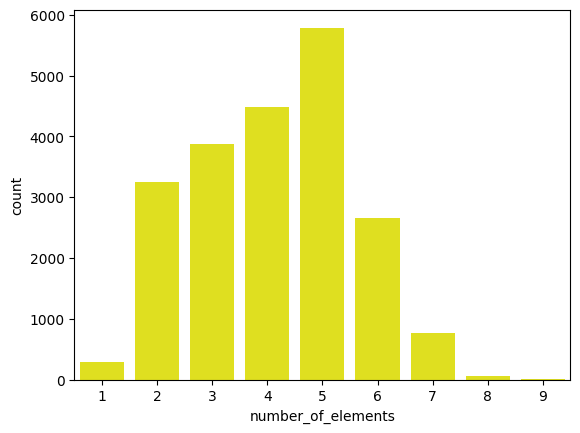

In [32]:
sns.countplot(x='number_of_elements', data=df,color='yellow')

<Axes: xlabel='number_of_elements', ylabel='critical_temp'>

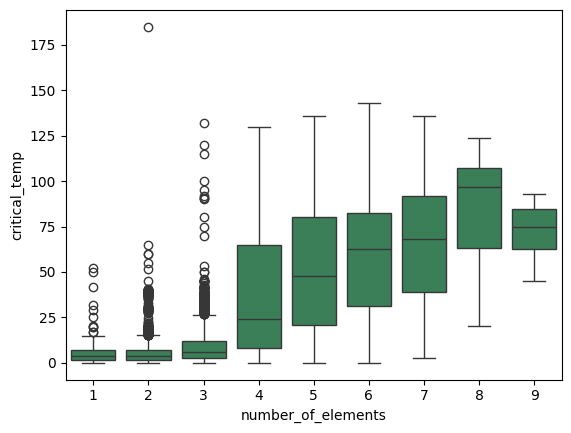

In [33]:
sns.boxplot(
    x='number_of_elements',
    y='critical_temp',
    data=df,
    color='seagreen'
)

Superconductors with more elements generally exhibit higher critical temperatures, with peak performance observed around 7–8 elements, indicating that **material complexity is an important factor in superconductivity**.

Tc_Category The feature contains information derived directly from the target.


**Model sees Tc_Category
Tc_Category already reveals Tc range
Model gets the answer indirectly**

**This is target leakage (data leakage).**

In [34]:
df.drop(['Tc_Category','Valence_Group','Thermal_Group'],axis=1 ,inplace = True)

        Property Family  Average Correlation
6               Valence             0.470021
1         Atomic Radius             0.426549
5  Thermal Conductivity             0.424505
0           Atomic Mass             0.376034
4           Fusion Heat             0.360769
2               Density             0.360599
3     Electron Affinity             0.250530


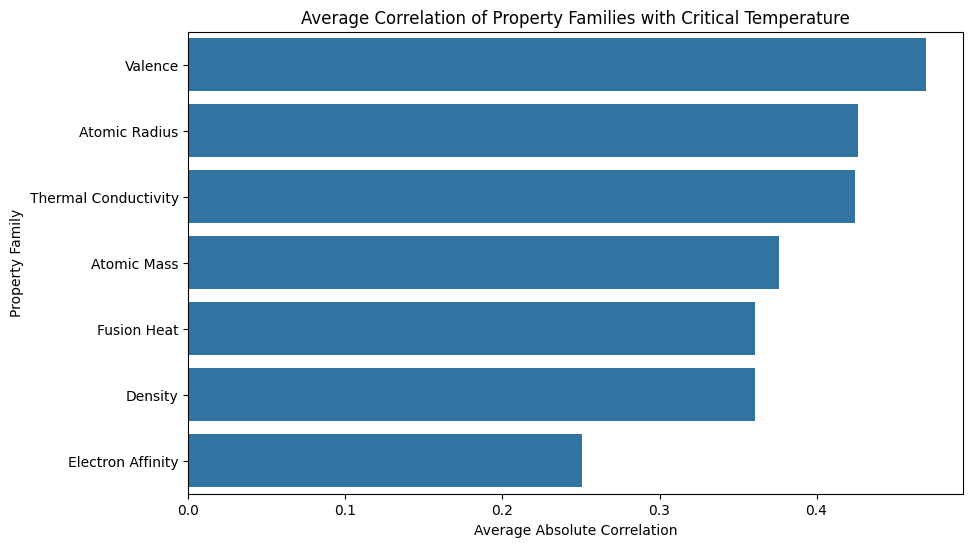

In [35]:
property_families = {
    'Atomic Mass': [col for col in df.columns if 'atomic_mass' in col],
    'Atomic Radius': [col for col in df.columns if 'atomic_radius' in col],
    'Density': [col for col in df.columns if 'Density' in col],
    'Electron Affinity': [col for col in df.columns if 'ElectronAffinity' in col],
    'Fusion Heat': [col for col in df.columns if 'FusionHeat' in col],
    'Thermal Conductivity': [col for col in df.columns if 'ThermalConductivity' in col],
    'Valence': [col for col in df.columns if 'Valence' in col]
}

family_corr = {}

for family, cols in property_families.items():

    corrs = []

    for col in cols:
        corr = abs(df[col].corr(df['critical_temp']))
        corrs.append(corr)

    family_corr[family] = np.mean(corrs)

family_corr_df = pd.DataFrame(
    family_corr.items(),
    columns=['Property Family', 'Average Correlation']
)

family_corr_df = family_corr_df.sort_values(
    by='Average Correlation',
    ascending=False
)

print(family_corr_df)
plt.figure(figsize=(10,6))

sns.barplot(
    data=family_corr_df,
    x='Average Correlation',
    y='Property Family'
)

plt.title('Average Correlation of Property Families with Critical Temperature')
plt.xlabel('Average Absolute Correlation')
plt.ylabel('Property Family')

plt.show()

**Valence-related properties exhibit the strongest overall relationship with critical temperature, making them the most influential property family in the dataset.**

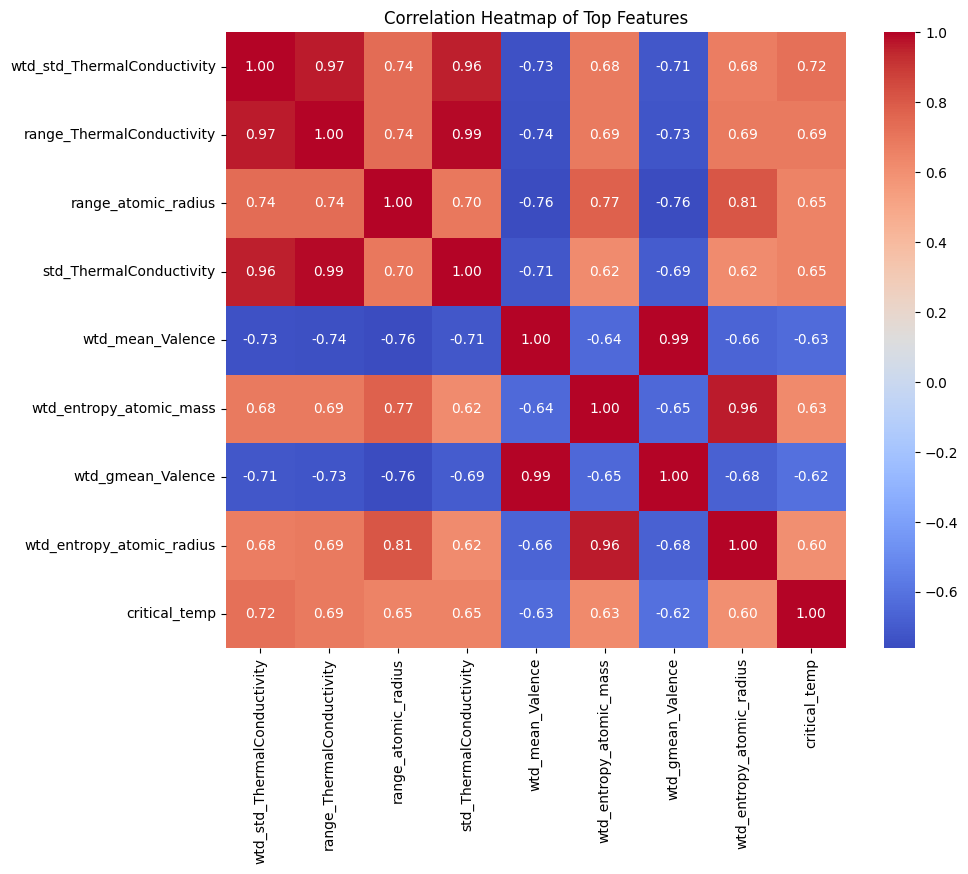

In [36]:
# Top 10 features most correlated with Tc

corr_tc = df.corr()['critical_temp'].abs().sort_values(ascending=False)

top_features = corr_tc.index[1:9].tolist()

heatmap_features = top_features + ['critical_temp']

plt.figure(figsize=(10,8))

sns.heatmap(
    df[heatmap_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Top Features')
plt.show()

### Insight

> The heatmap reveals that Thermal Conductivity and Valence-related features are among the strongest predictors of critical temperature. In particular, weighted thermal conductivity variability exhibits the highest positive correlation with Tc (r = 0.72), whereas weighted mean valence shows a strong negative relationship (r = -0.63).

> The analysis also highlights substantial multicollinearity among several top predictors, especially within the Thermal Conductivity and Valence feature groups. This suggests that many features capture similar underlying material characteristics and may provide overlapping information to predictive models.

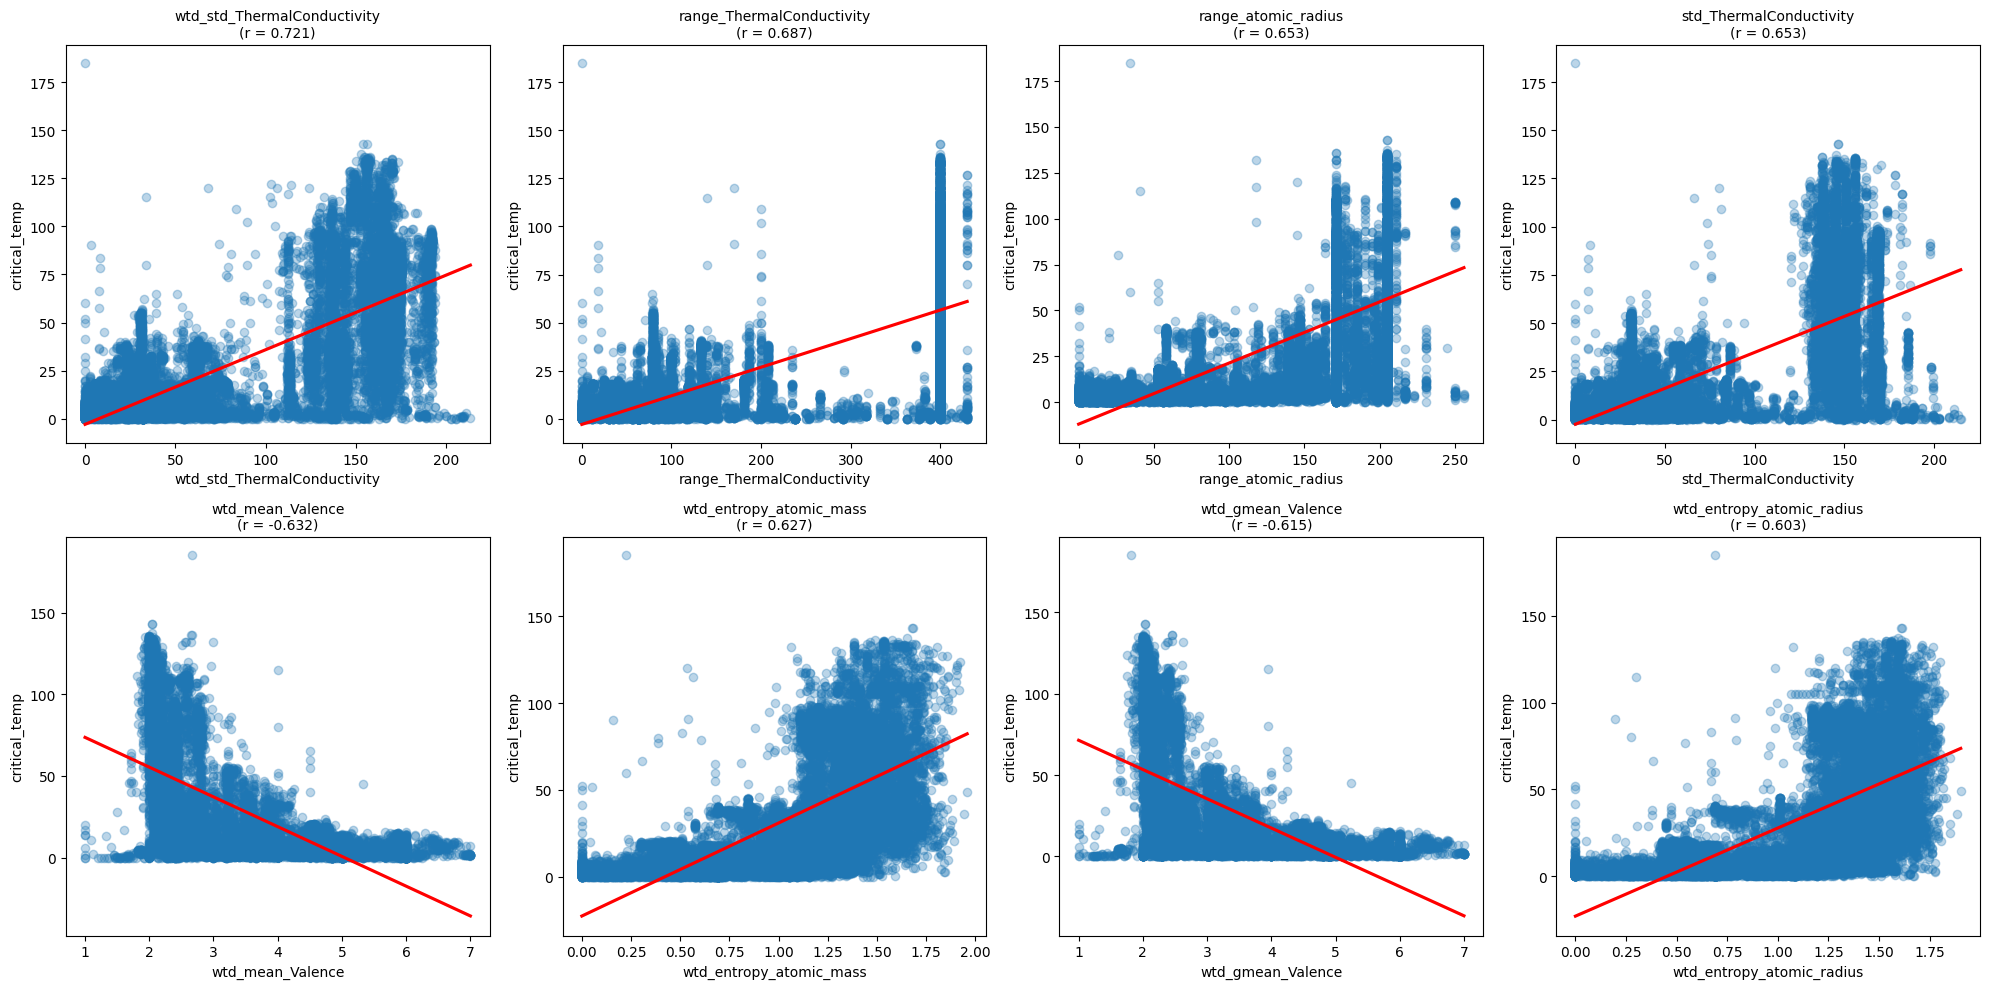

In [37]:
fig, axes = plt.subplots(2, 4, figsize=(20,10))
axes = axes.flatten()

for i, feature in enumerate(top_features):

    # Calculate Pearson correlation
    corr = df[feature].corr(df['critical_temp'])

    sns.regplot(
        data=df,
        x=feature,
        y='critical_temp',
        scatter_kws={'alpha':0.3},
        line_kws={'color':'red'},
        ax=axes[i]
    )

    axes[i].set_title(
        f"{feature}\n(r = {corr:.3f})",
        fontsize=10
    )

plt.tight_layout()
plt.show()

#3. Splitting Data

In [38]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [39]:
# Features
X = df.drop('critical_temp', axis=1)

# Target
y = df['critical_temp']


In [40]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)


In [41]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Modelling

# Linear regression

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,root_mean_squared_error
)


In [43]:

lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)

In [44]:
y_predlr_train = lr.predict(X_train_scaled)

In [45]:
print("____________________test_______________________")
print("R2 score :",r2_score(y_test,y_pred))
print("MAE score :",mean_absolute_error(y_test,y_pred))
print("RMSE score :",root_mean_squared_error(y_test,y_pred))
print("___________________train_________________________")
print("R2 score :",r2_score(y_train,y_predlr_train))
print("MAE score :",mean_absolute_error(y_train,y_predlr_train))
print("RMSE score :",root_mean_squared_error(y_train,y_predlr_train))

____________________test_______________________
R2 score : 0.7353599049007871
MAE score : 13.269651778791143
RMSE score : 17.649934563711955
___________________train_________________________
R2 score : 0.7371059982879336
MAE score : 13.3245774260243
RMSE score : 17.569863760643134


1. Key Observation 1: No Overfitting
2. Key Observation 2: Moderate Predictive Performance
(The model explains approximately 73.5% of the variation in critical temperature.)

#Random Forest

In [46]:
from sklearn.ensemble import RandomForestRegressor

In [47]:
RFG_model = RandomForestRegressor(n_estimators=300,max_depth=20,min_samples_split=5
                                 ,min_samples_leaf=2,max_features='sqrt',n_jobs=-1)

In [48]:
RFG_model.fit(X_train,y_train)

RandomForestRegressor(max_depth=20, max_features='sqrt', min_samples_leaf=2,
                      min_samples_split=5, n_estimators=300, n_jobs=-1)

In [49]:
y_predRFG = RFG_model.predict(X_test)
y_predRFG_train = RFG_model.predict(X_train)

In [50]:
print("____________________test_______________________")
print("R2 score :",r2_score(y_test,y_predRFG))
print("MAE score :",mean_absolute_error(y_test,y_predRFG))
print("RMSE score :",root_mean_squared_error(y_test,y_predRFG))
print("___________________train_________________________")
print("R2 score :",r2_score(y_train,y_predRFG_train))
print("MAE score :",mean_absolute_error(y_train,y_predRFG_train))
print("RMSE score :",root_mean_squared_error(y_train,y_predRFG_train))

____________________test_______________________
R2 score : 0.9253586025189013
MAE score : 5.282024269880888
RMSE score : 9.373572841211232
___________________train_________________________
R2 score : 0.9697045837772652
MAE score : 3.2902896560241706
RMSE score : 5.96439664312016


**Key Observation** 1 : Excellent Predictive Performance
The Random Forest model explains approximately 92.5% of the variation in critical temperature.

**Key Observation** 2: Captures Non-Linear Relationships

| Model             | Test R² |
| ----------------- | ------- |
| Linear Regression | 0.735   |
| Random Forest     | 0.925   |


**Random Forest captures complex non-linear interactions between material properties that Linear Regression cannot model effectively.**

In [51]:
feature_importancerf = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': RFG_model.feature_importances_
})

feature_importancerf = feature_importancerf.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importancerf.head(20))

                          Feature  Importance
67      range_ThermalConductivity    0.074882
70    wtd_std_ThermalConductivity    0.068682
69        std_ThermalConductivity    0.060186
27            range_atomic_radius    0.051990
74              wtd_gmean_Valence    0.051218
76            wtd_entropy_Valence    0.050278
72               wtd_mean_Valence    0.050121
17                      range_fie    0.039021
6         wtd_entropy_atomic_mass    0.032983
62   wtd_mean_ThermalConductivity    0.023009
75                entropy_Valence    0.021808
33                  gmean_Density    0.021739
73                  gmean_Valence    0.021286
64  wtd_gmean_ThermalConductivity    0.019679
50       wtd_std_ElectronAffinity    0.018762
26      wtd_entropy_atomic_radius    0.016477
56         wtd_entropy_FusionHeat    0.014989
44     wtd_gmean_ElectronAffinity    0.014858
68  wtd_range_ThermalConductivity    0.014308
71                   mean_Valence    0.013124


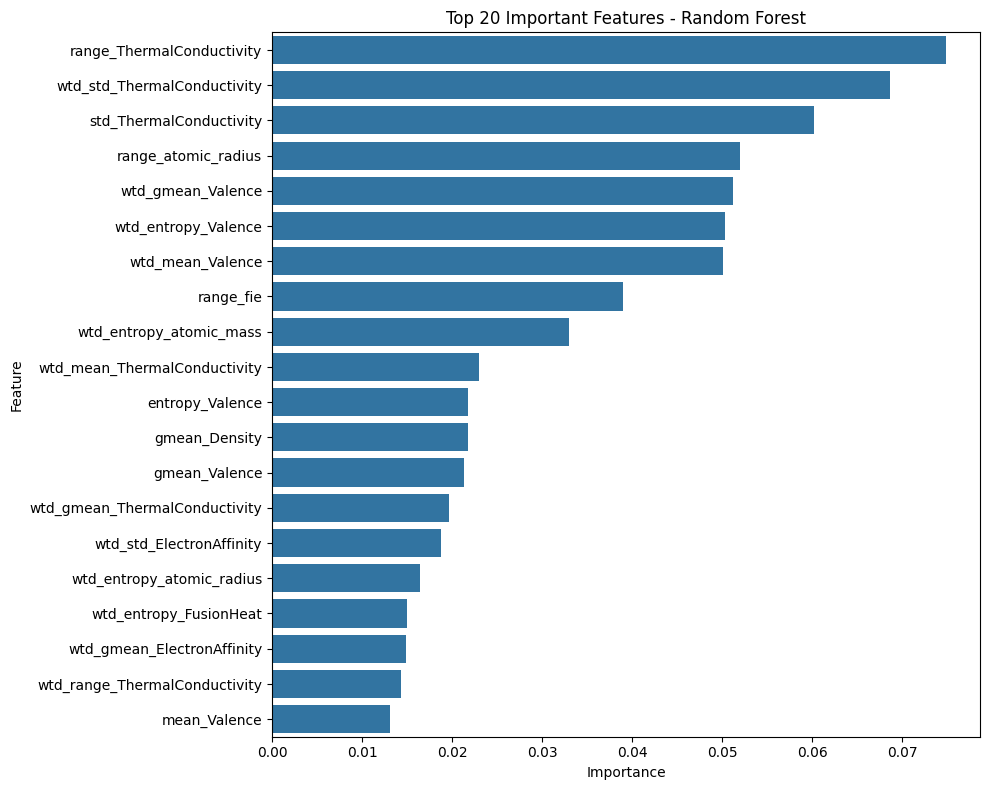

In [57]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Get feature importance from your trained Random Forest model
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': RFG_model.feature_importances_
})

# Sort features from most to least important
feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

# Plot top 20 features
plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(20),
    x='Importance',
    y='Feature'
)

plt.title('Top 20 Important Features - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

#XGBoost

In [58]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [59]:


xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train)

y_predXGB = xgb.predict(X_test)
y_predXGB_train = xgb.predict(X_train)

In [60]:
print("____________________test_______________________")
print("R2 score :",r2_score(y_test,y_predXGB))
print("MAE score :",mean_absolute_error(y_test,y_predXGB))
print("RMSE score :",root_mean_squared_error(y_test,y_predXGB))
print("___________________train_________________________")
print("R2 score :",r2_score(y_train,y_predXGB_train))
print("MAE score :",mean_absolute_error(y_train,y_predXGB_train))
print("RMSE score :",root_mean_squared_error(y_train,y_predXGB_train))

____________________test_______________________
R2 score : 0.9263691078132943
MAE score : 5.556567226611732
RMSE score : 9.309906279363558
___________________train_________________________
R2 score : 0.9669162222094824
MAE score : 3.946654987981527
RMSE score : 6.232834610057054


**Key Observation 1: Best Overall Model** XGBoost achieved the highest test R² score, explaining approximately 92.6% of the variance in critical temperature.


**Key Observation 2: Lowest RMSE**
XGBoost produced the lowest RMSE, indicating slightly more accurate predictions on unseen data.

**Key Observation 3: Mild Overfitting**
The model exhibits mild overfitting, but the gap between training and testing performance remains small, indicating good generalization capability.

In [61]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(20))

                            Feature  Importance
67        range_ThermalConductivity    0.648570
27              range_atomic_radius    0.112166
64    wtd_gmean_ThermalConductivity    0.033622
50         wtd_std_ElectronAffinity    0.014595
9                   std_atomic_mass    0.013889
70      wtd_std_ThermalConductivity    0.012870
62     wtd_mean_ThermalConductivity    0.011642
74                wtd_gmean_Valence    0.008772
43           gmean_ElectronAffinity    0.007181
47           range_ElectronAffinity    0.006992
72                 wtd_mean_Valence    0.005851
33                    gmean_Density    0.004938
66  wtd_entropy_ThermalConductivity    0.004639
73                    gmean_Valence    0.004527
39                      std_Density    0.004497
31                     mean_Density    0.004334
17                        range_fie    0.004228
49             std_ElectronAffinity    0.003999
35                  entropy_Density    0.003721
80                  wtd_std_Valence    0

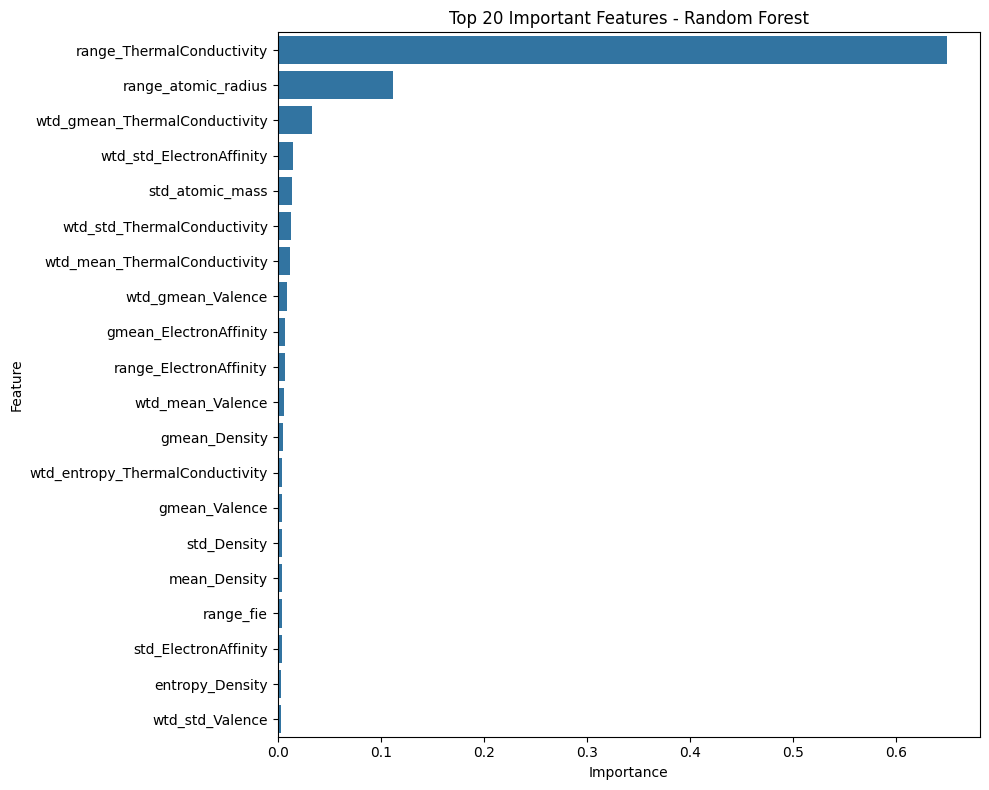

In [68]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

sns.barplot(
    data=feature_importance.head(20),
    x='Importance',
    y='Feature'
)

plt.title('Top 20 Important Features - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

### XGBoost Performance

The XGBoost model achieved the highest predictive performance among all evaluated models, with a test R² score of 0.926. The model explains approximately 92.6% of the variance in critical temperature while maintaining relatively low prediction errors (MAE = 5.57 K, RMSE = 9.33 K).

Although a small gap exists between training and testing performance, the model demonstrates strong generalization and only mild overfitting. The superior performance compared with Linear Regression highlights the importance of capturing complex non-linear relationships within superconducting materials.

Overall, XGBoost emerged as the most effective model for predicting superconducting critical temperature.

| Model             |   Test R² | Test MAE | Test RMSE |
| ----------------- | --------: | -------: | --------: |
| Linear Regression |     0.735 |    13.27 |     17.65 |
| Random Forest     |     0.925 |     5.28 |      9.38 |
| XGBoost           | **0.926** |     5.57 |  **9.33** |


In [77]:
import joblib

joblib.dump(xgb, "model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [78]:
from google.colab import files

files.download("model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [75]:
import joblib

model = joblib.load("model.pkl")

print("Model loaded successfully!")
print("Model type:", type(model))

Model loaded successfully!
Model type: <class 'xgboost.sklearn.XGBRegressor'>


In [79]:
import xgboost as xgb

print("Model variable type:", type(xgb))

Model variable type: <class 'module'>


In [80]:
print(type(XGBRegressor))
print(type(xgb))


<class 'type'>
<class 'module'>


In [81]:
from sklearn.base import BaseEstimator

for name, obj in globals().copy().items():
    if isinstance(obj, BaseEstimator) and hasattr(obj, "predict"):
        print(name, type(obj))

__ <class 'sklearn.ensemble._forest.RandomForestRegressor'>
lr <class 'sklearn.linear_model._base.LinearRegression'>
RFG_model <class 'sklearn.ensemble._forest.RandomForestRegressor'>
_48 <class 'sklearn.ensemble._forest.RandomForestRegressor'>
model <class 'xgboost.sklearn.XGBRegressor'>


In [89]:
from sklearn.base import BaseEstimator

for name, obj in list(globals().items()):
    if isinstance(obj, BaseEstimator) and hasattr(obj, "predict"):
        print(name, type(obj))

__ <class 'sklearn.ensemble._forest.RandomForestRegressor'>
lr <class 'sklearn.linear_model._base.LinearRegression'>
RFG_model <class 'sklearn.ensemble._forest.RandomForestRegressor'>
_48 <class 'sklearn.ensemble._forest.RandomForestRegressor'>
model <class 'xgboost.sklearn.XGBRegressor'>


In [90]:
model.save_model("superconductor_model.json")

print("XGBoost model saved successfully!")

XGBoost model saved successfully!


In [91]:
from google.colab import files

files.download("superconductor_model.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>